# Statistical analysis: AI Job Market & Interview Coach

Data is read from **PostgreSQL** with the read-only role (`DATABASE_URL`). Two sources are analysed **separately** (never pooled): `data_jobs` 2023 (784,897 data-role postings) and the Arbeitnow API snapshot of 2026-10-08 (3,026 postings, all occupations).

Principles: (1) every test states H0/H1, assumptions and an **effect size**: with hundreds of thousands of rows almost everything is 'significant'; (2) observational data: **associations, not causes**.

In [1]:
import json, os, sys
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, os.path.abspath('..'))
from market.stats import analyses as A
from market.stats import run_stats as R
from market.stats.data import reference_jobs, live_jobs, reference_skill_matrix, query_df
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
R.style()
ref, live = reference_jobs(), live_jobs()
print(ref.shape, live.shape)

(784897, 16) (3026, 11)


## 1. Descriptive statistics

In [2]:
desc = A.descriptive_tables(ref, live)
pd.DataFrame({'reference skill_count': desc['reference_skill_count'], 'reference salary (USD/yr)': desc['reference_salary_year'],
              'live skill_count': desc['live_skill_count'], 'live description words': desc['live_description_words']})

,reference skill_count,reference salary (USD/yr),live skill_count,live description words
n,667989.000,21997.000,3026.000,3026.000
mean,5.474,123292.218,3.671,582.003
sd,3.837,48316.796,3.689,281.987
median,5.000,115000.000,2.000,528.500
q1,3.000,90000.000,1.000,386.000
q3,7.000,150000.000,5.000,725.000
min,1.000,15000.000,0.000,9.000
max,53.000,960000.000,35.000,2330.000
skewness,1.434,1.746,1.810,1.432


In [3]:
pd.DataFrame(desc['reference_skill_count_by_role']).T[['n','mean','sd','median','q1','q3','skewness']]

,n,mean,sd,median,q1,q3,skewness
Business Analyst,36724.0,3.614,2.590,3.0,2.0,5.0,1.658
Cloud Engineer,8961.0,5.183,4.052,4.0,2.0,7.0,1.375
Data Analyst,184080.0,4.085,2.767,3.0,2.0,5.0,1.500
Data Engineer,210744.0,6.865,4.263,6.0,4.0,9.0,1.141
Data Scientist,177729.0,5.530,3.715,5.0,3.0,7.0,1.453
Machine Learning Engineer,12164.0,6.327,4.119,6.0,3.0,9.0,1.101
Software Engineer,37587.0,5.816,4.126,5.0,3.0,8.0,1.339


In [4]:
pd.DataFrame(desc['live_skill_count_by_family']).T[['n','mean','sd','median','q1','q3','skewness']].sort_values('n', ascending=False)

,n,mean,sd,median,q1,q3,skewness
Software & IT,522.0,5.264,4.699,4.0,1.0,8.0,1.151
Management & Consulting,465.0,2.794,2.565,2.0,1.0,4.0,1.224
Sales & Business Development,338.0,2.953,2.183,3.0,1.0,4.0,0.932
Engineering & Technical,323.0,3.920,3.948,3.0,1.0,6.0,1.273
Marketing & Communication,313.0,2.588,2.109,2.0,1.0,4.0,1.335
Data & AI,306.0,7.418,4.726,7.0,4.0,10.0,1.170
Other,280.0,2.650,2.575,2.0,1.0,4.0,1.442
Finance & Accounting,244.0,1.775,1.611,1.0,1.0,2.0,1.648
Operations & Logistics,98.0,2.816,2.312,2.0,1.0,4.0,1.281
HR & Recruiting,91.0,1.857,2.079,1.0,0.5,3.0,2.562


Skill counts are **right-skewed** (skewness > 0.9 in every group): rank-based tests are used for them.

## 2. Question A: do senior postings list more skills? (data_jobs 2023)
- H0: within each role family, senior and non-senior skill-count distributions are equal.
- H1: they differ (two-sided).
- Test: Mann-Whitney U per role family (Holm correction); effect size Cliff's δ.

In [5]:
a = A.senior_skill_count_test(ref)
pd.DataFrame(a['results'])[['role_family','n_senior','n_non_senior','mean_senior','mean_non_senior','mean_difference','mean_difference_ci95','p_holm','cliffs_delta','effect','prob_senior_lists_more']]

,role_family,n_senior,n_non_senior,mean_senior,mean_non_senior,mean_difference,mean_difference_ci95,p_holm,cliffs_delta,effect,prob_senior_lists_more
0,Data Analyst,24852,159228,4.702,3.989,0.713,"[0.674, 0.752]",0.000000e+00,0.1526,small,0.5763
1,Data Engineer,41594,169150,7.554,6.696,0.857,"[0.811, 0.904]",0.000000e+00,0.1252,negligible,0.5626
2,Data Scientist,32060,145669,5.735,5.485,0.250,"[0.205, 0.295]",1.072604e-41,0.0479,negligible,0.5240


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


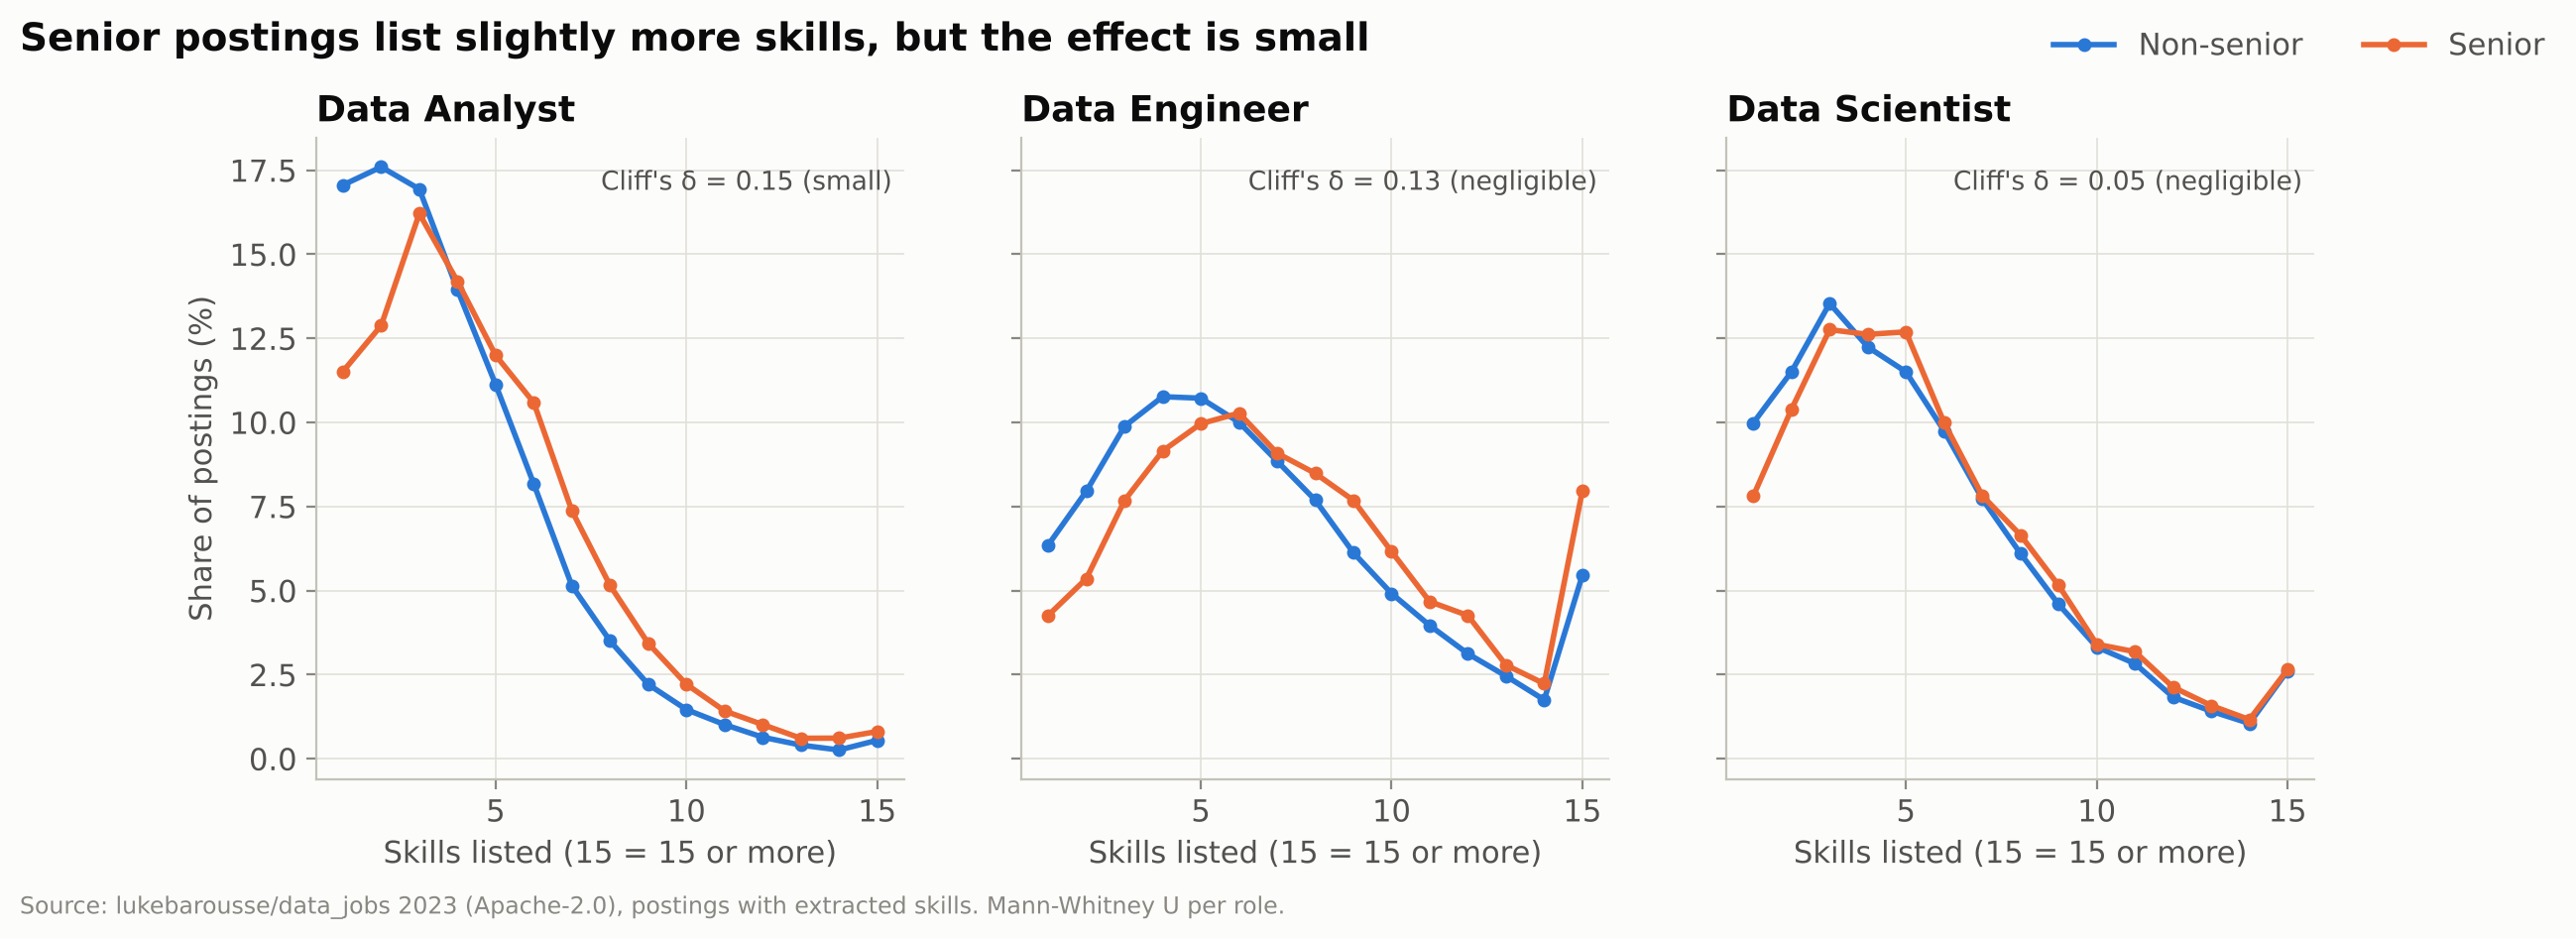

In [6]:
R.fig_skill_count_by_seniority(ref, a)
display(Image(str(R.FIG_DIR / 'A_skill_count_by_seniority.png'), width=900))

**Interpretation:** H0 is rejected for all three roles (p < 1e-40), but the effect is **small for Data Analysts and negligible for Data Engineers and Data Scientists**. A senior posting has only a 52-58% chance of listing more skills than a non-senior one. Seniority is not mainly expressed by a longer skill list.

## 3. Question B: is remote work associated with the job family?
- H0: remote status is independent of role/job family. H1: it is not.
- Test: Pearson chi-square of independence (expected-count rule checked); effect size Cramér's V. Run **separately** on each source.

In [7]:
b_ref = A.remote_association_test(ref, 'role_family', 'work_from_home', 'data_jobs 2023')
b_live = A.remote_association_test(live, 'job_family', 'remote', 'Arbeitnow snapshot 2026')
pd.DataFrame([{k: b[k] for k in ['question','n','chi2','dof','p_value','cramers_v','effect','assumptions']} for b in (b_ref, b_live)])

,question,n,chi2,dof,p_value,cramers_v,effect,assumptions
0,Is remote work associated with the role family...,784897,5122.148,6,0.000000e+00,0.0808,negligible,Independent postings; expected counts >= 5 in ...
1,Is remote work associated with the job family?...,3026,65.191,10,3.725568e-10,0.1468,small,Independent postings; expected counts >= 5 in ...


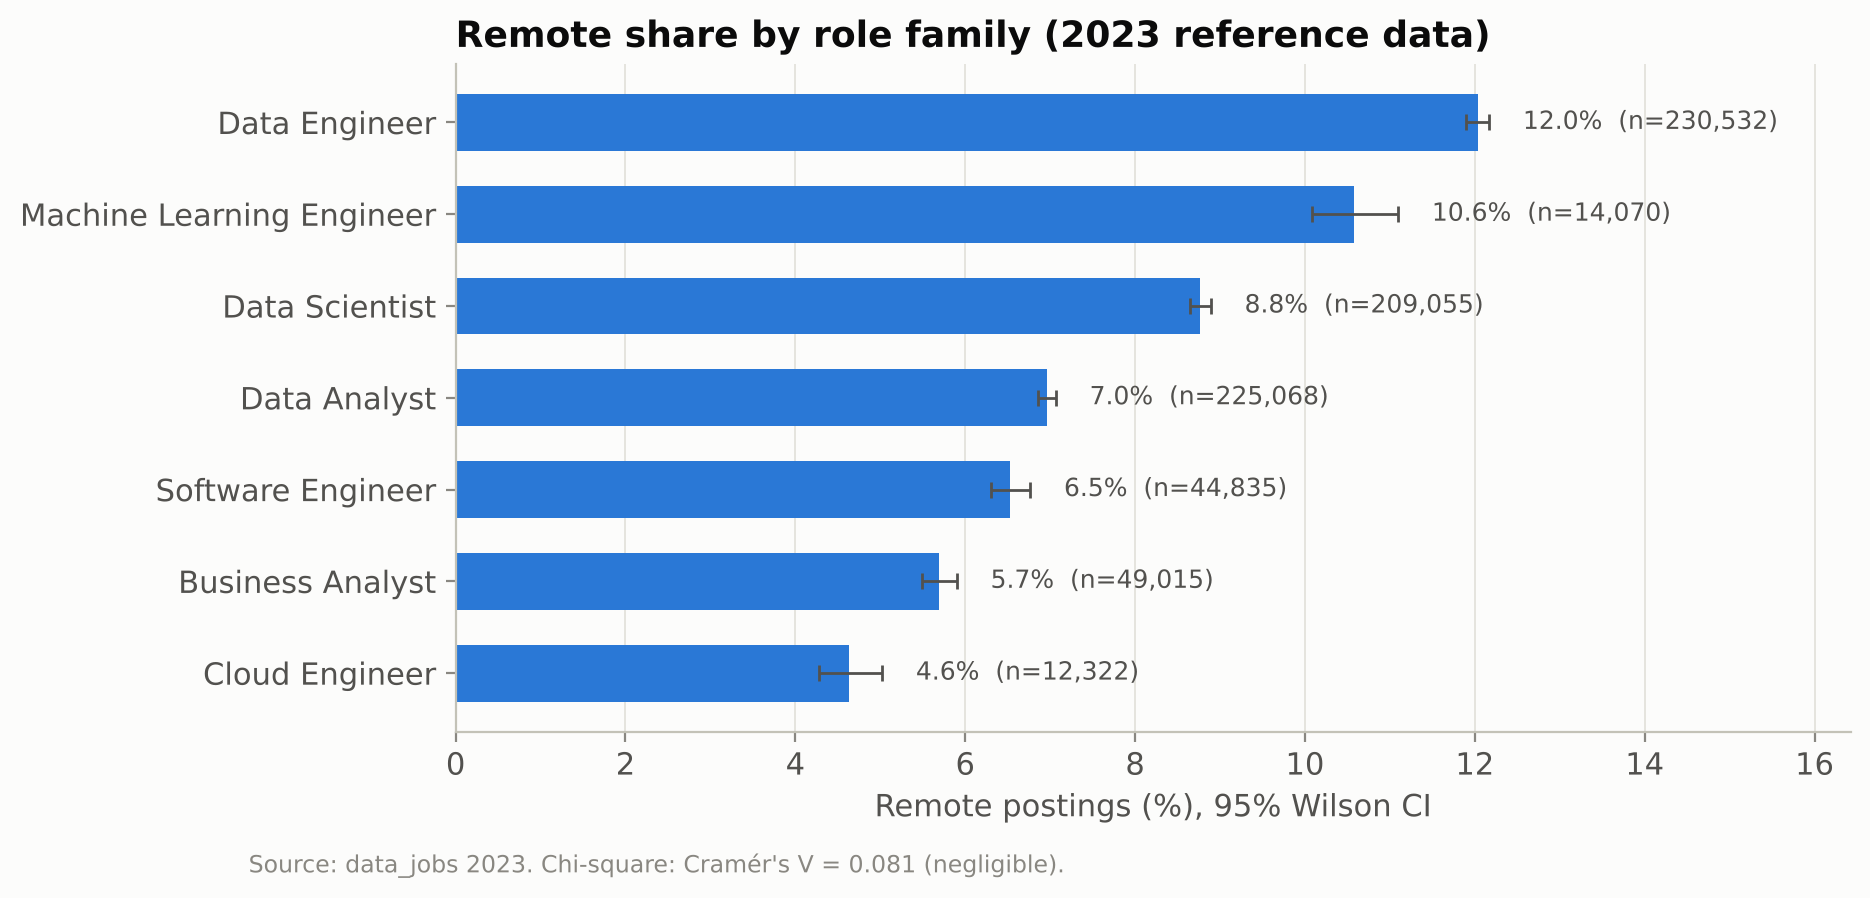

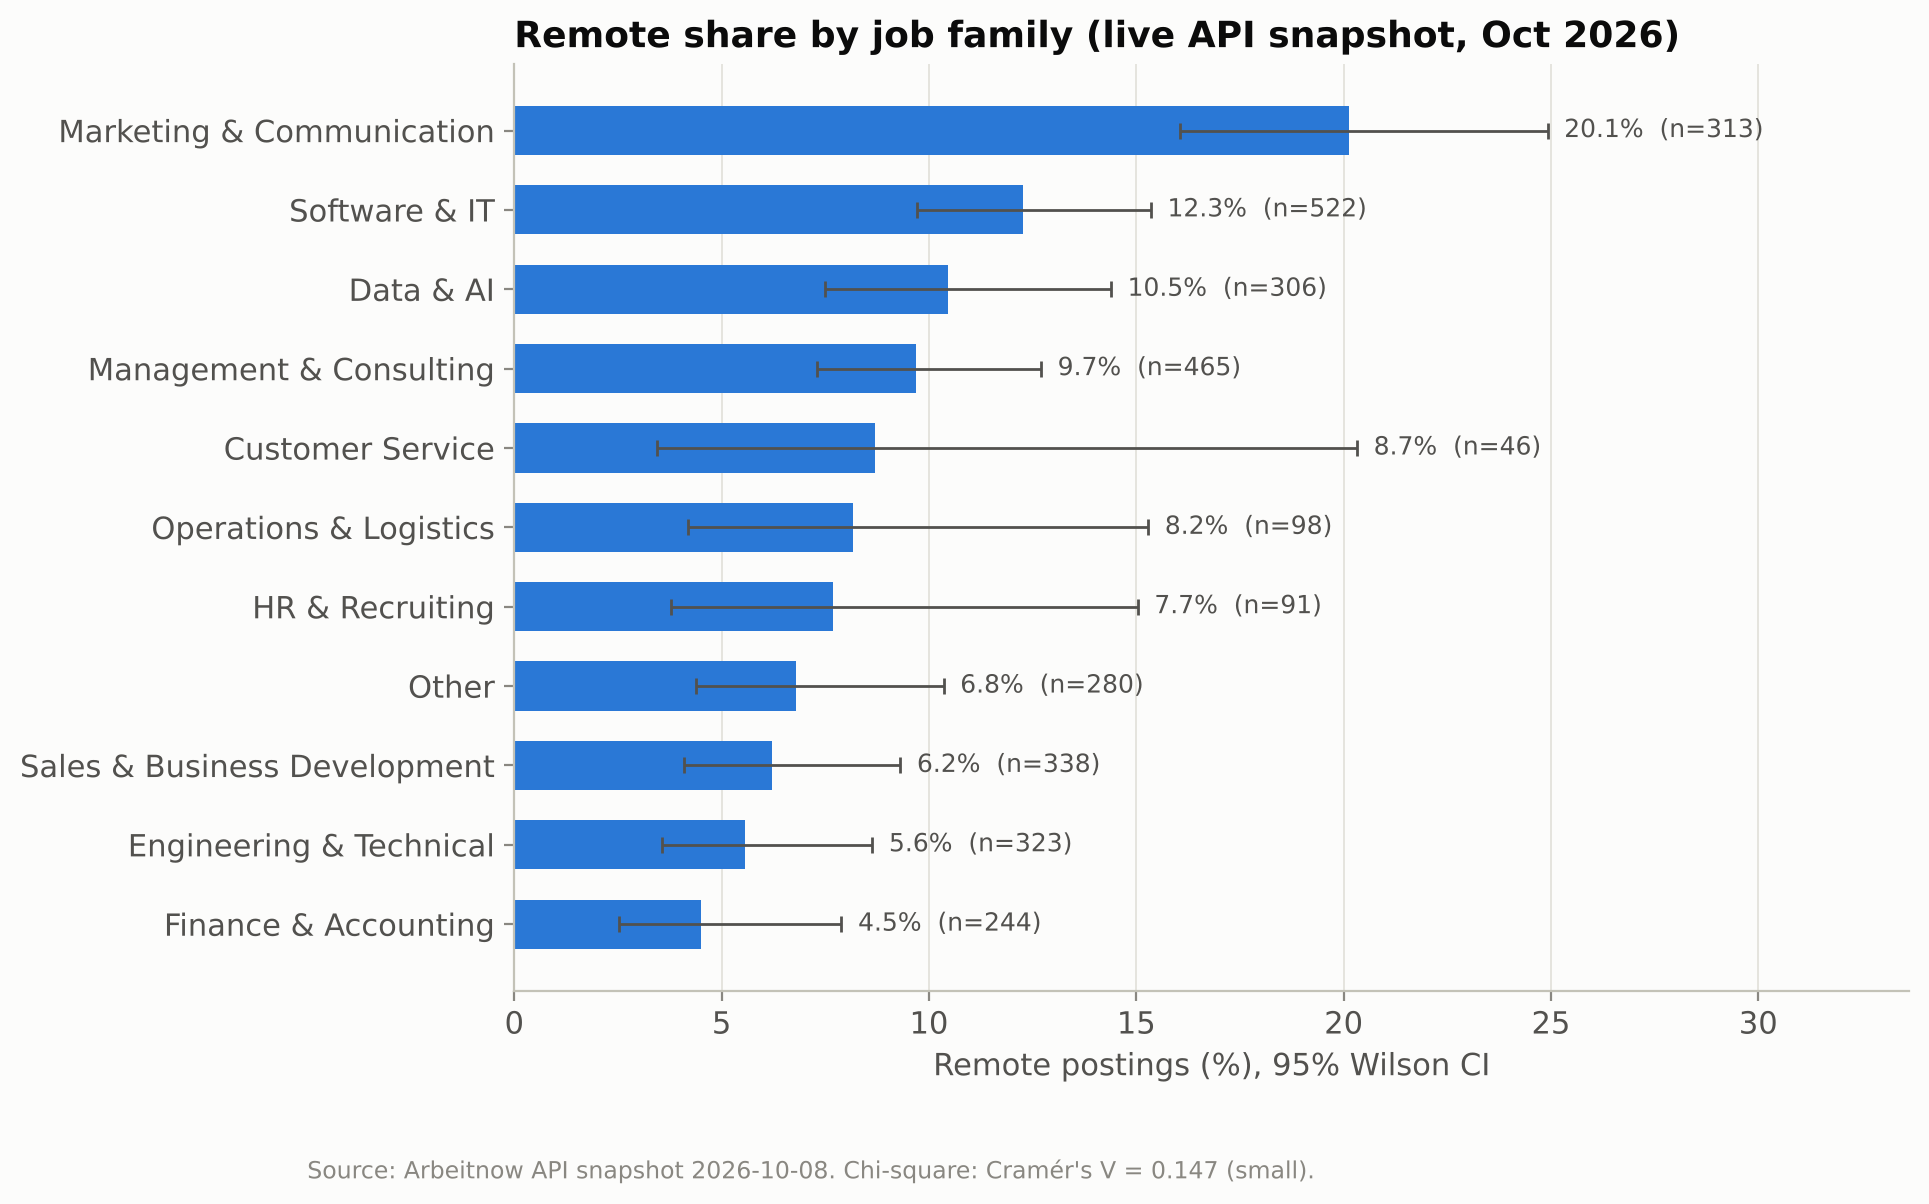

In [8]:
R.fig_remote_share(ref, 'role_family', 'work_from_home', 'Remote share by role family (2023 reference data)', 'B_remote_by_role_reference', f"Source: data_jobs 2023. Chi-square: Cramér's V = {b_ref['cramers_v']:.3f} ({b_ref['effect']}).")
R.fig_remote_share(live, 'job_family', 'remote', 'Remote share by job family (live API snapshot, Oct 2026)', 'B_remote_by_family_live', f"Source: Arbeitnow API snapshot 2026-10-08. Chi-square: Cramér's V = {b_live['cramers_v']:.3f} ({b_live['effect']}).")
display(Image(str(R.FIG_DIR / 'B_remote_by_role_reference.png'), width=700)); display(Image(str(R.FIG_DIR / 'B_remote_by_family_live.png'), width=700))

**Interpretation:** both tests reject independence, but in 2023 data roles the association is **negligible** (remote share 4.6-12.0% across roles). In the 2026 snapshot it is **small**: Marketing & Communication stands out (20.1% remote). The two sources are different populations, so the numbers are not compared over time.

## 4. Question C: which skills are over-represented in senior postings, within the same role?
- For each skill: H0 common odds ratio = 1 across the three role strata; H1 ≠ 1.
- Test: Cochran-Mantel-Haenszel (controls for role mix), Benjamini-Hochberg FDR 5%; effect size MH odds ratio.

In [9]:
skills = query_df('SELECT s.name FROM market.job_skills_reference js JOIN market.skills s USING (skill_id) GROUP BY s.name HAVING COUNT(*) >= %s', (5000,))['name'].tolist()
c = A.senior_skill_association(ref, reference_skill_matrix(skills))
res_c = pd.DataFrame(c['results'])
print(c['data']); print('skills tested:', len(res_c), '| significant at 5% FDR:', int(res_c.significant_fdr_5pct.sum()),
      '| heterogeneous across roles (Breslow-Day p<0.05):', int((res_c.homogeneity_p < 0.05).sum()))
pd.concat([res_c.head(10), res_c.tail(5)])[['skill','senior_share_pct','non_senior_share_pct','mh_odds_ratio','or_ci95','q_value_bh','homogeneity_p']]

data_jobs 2023, 572,553 postings with skills in Data Analyst, Data Engineer, Data Scientist; skills present in >= 5,000 of them
skills tested: 71 | significant at 5% FDR: 64 | heterogeneous across roles (Breslow-Day p<0.05): 65


,skill,senior_share_pct,non_senior_share_pct,mh_odds_ratio,or_ci95,q_value_bh,homogeneity_p
0,looker,4.84,2.83,1.844,"[1.782, 1.908]",0.0,0.000000e+00
1,redshift,8.53,4.86,1.650,"[1.607, 1.695]",0.0,0.000000e+00
2,Snowflake,13.16,8.12,1.589,"[1.555, 1.624]",0.0,0.000000e+00
3,Airflow,10.84,6.62,1.536,"[1.499, 1.573]",0.0,2.940069e-08
4,Terraform,3.94,2.33,1.491,"[1.435, 1.548]",0.0,7.133303e-02
5,AWS,29.32,20.51,1.465,"[1.441, 1.489]",0.0,1.374836e-06
6,dynamodb,1.53,0.93,1.434,"[1.352, 1.522]",0.0,2.345802e-07
7,Kafka,10.94,7.13,1.412,"[1.379, 1.447]",0.0,2.652323e-11
8,BigQuery,5.21,3.58,1.383,"[1.339, 1.428]",0.0,4.942782e-09
9,Kubernetes,6.50,4.24,1.381,"[1.341, 1.422]",0.0,1.631382e-01


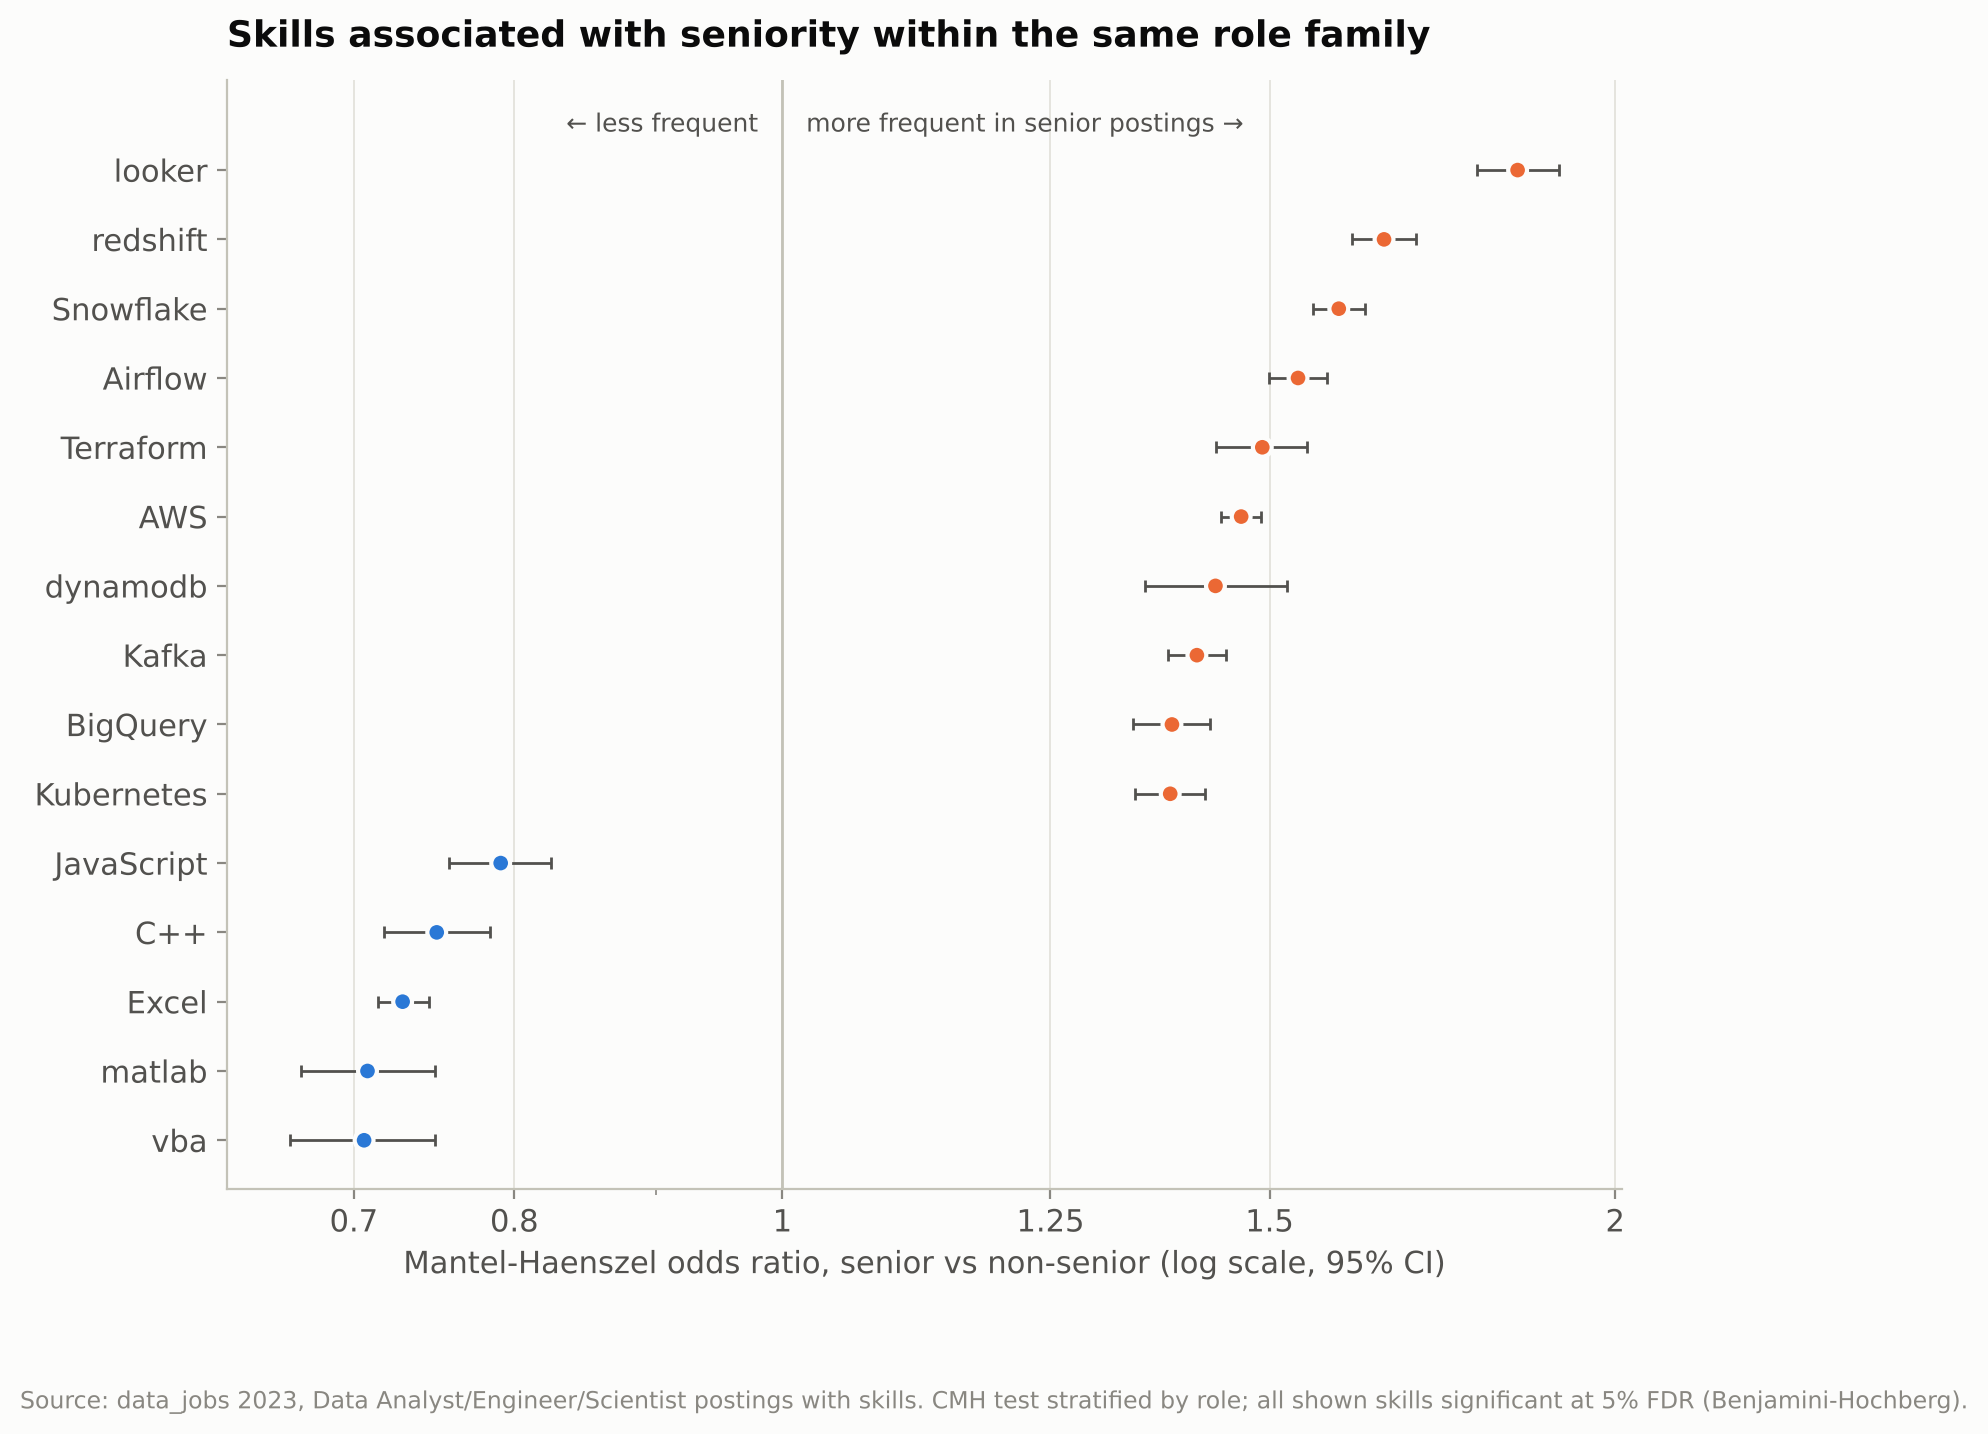

In [10]:
R.fig_senior_odds_ratios(c)
display(Image(str(R.FIG_DIR / 'C_senior_skill_odds_ratios.png'), width=750))

**Interpretation:** data-platform and cloud tools (Looker, Redshift, Snowflake, Airflow, Terraform, AWS, Kafka) are 1.4-1.8× more likely (odds) to appear in senior postings of the same role; Excel, VBA, MATLAB and C++ are less likely. Many associations differ in strength between roles (Breslow-Day), so the pooled odds ratio is an average.

## 5. Question D: what is the advertised salary associated with? (statsmodels OLS)
- Model: log(salary) ~ role family + senior + remote + skill count; US postings only (currency/country held constant); HC3 robust standard errors.
- H0 for each coefficient: = 0.

In [11]:
d = A.salary_model(ref)
print(d['data']); print('R² =', d['r_squared'], '| adj. R² =', d['adj_r_squared'])
print(json.dumps(d['assumptions'], indent=1))
pd.DataFrame(d['coefficients'])

data_jobs 2023, United States, postings with an annual salary and extracted skills; n = 15,417; roles with < 100 salaries excluded: {'Cloud Engineer': 19}
R² = 0.2613 | adj. R² = 0.2609
{
 "log_salary_skewness": -0.12,
 "residual_skewness": 0.06,
 "residual_excess_kurtosis": 1.123,
 "breusch_pagan_p": 1.0914934040096896e-53,
 "note": "Breusch-Pagan tests constant residual variance; HC3 standard errors are used either way. Residual skewness/kurtosis checks approximate normality (inference relies mostly on the large n). VIF < 5 indicates no problematic multicollinearity.",
 "vif": {
  "C(role_family, Treatment('Data Analyst'))[T.Business Analyst]": 1.06,
  "C(role_family, Treatment('Data Analyst'))[T.Data Engineer]": 1.54,
  "C(role_family, Treatment('Data Analyst'))[T.Data Scientist]": 1.41,
  "C(role_family, Treatment('Data Analyst'))[T.Machine Learning Engineer]": 1.02,
  "C(role_family, Treatment('Data Analyst'))[T.Software Engineer]": 1.02,
  "is_senior": 1.02,
  "work_from_home": 1

,term,coef,pct_effect,ci95_pct,p_value
0,role: Business Analyst,0.0311,3.16,"[-0.03, 6.46]",5.213573e-02
1,role: Data Engineer,0.3321,39.38,"[37.59, 41.19]",0.000000e+00
2,role: Data Scientist,0.3591,43.20,"[41.42, 45.01]",0.000000e+00
3,role: Machine Learning Engineer,0.4755,60.88,"[50.87, 71.55]",2.198114e-47
4,role: Software Engineer,0.3636,43.85,"[35.6, 52.6]",2.164212e-33
5,is_senior,0.1584,17.16,"[15.92, 18.42]",1.018260e-180
6,work_from_home,0.0262,2.66,"[1.39, 3.93]",3.294946e-05
7,skill_count,0.0029,0.29,"[0.16, 0.43]",1.744164e-05


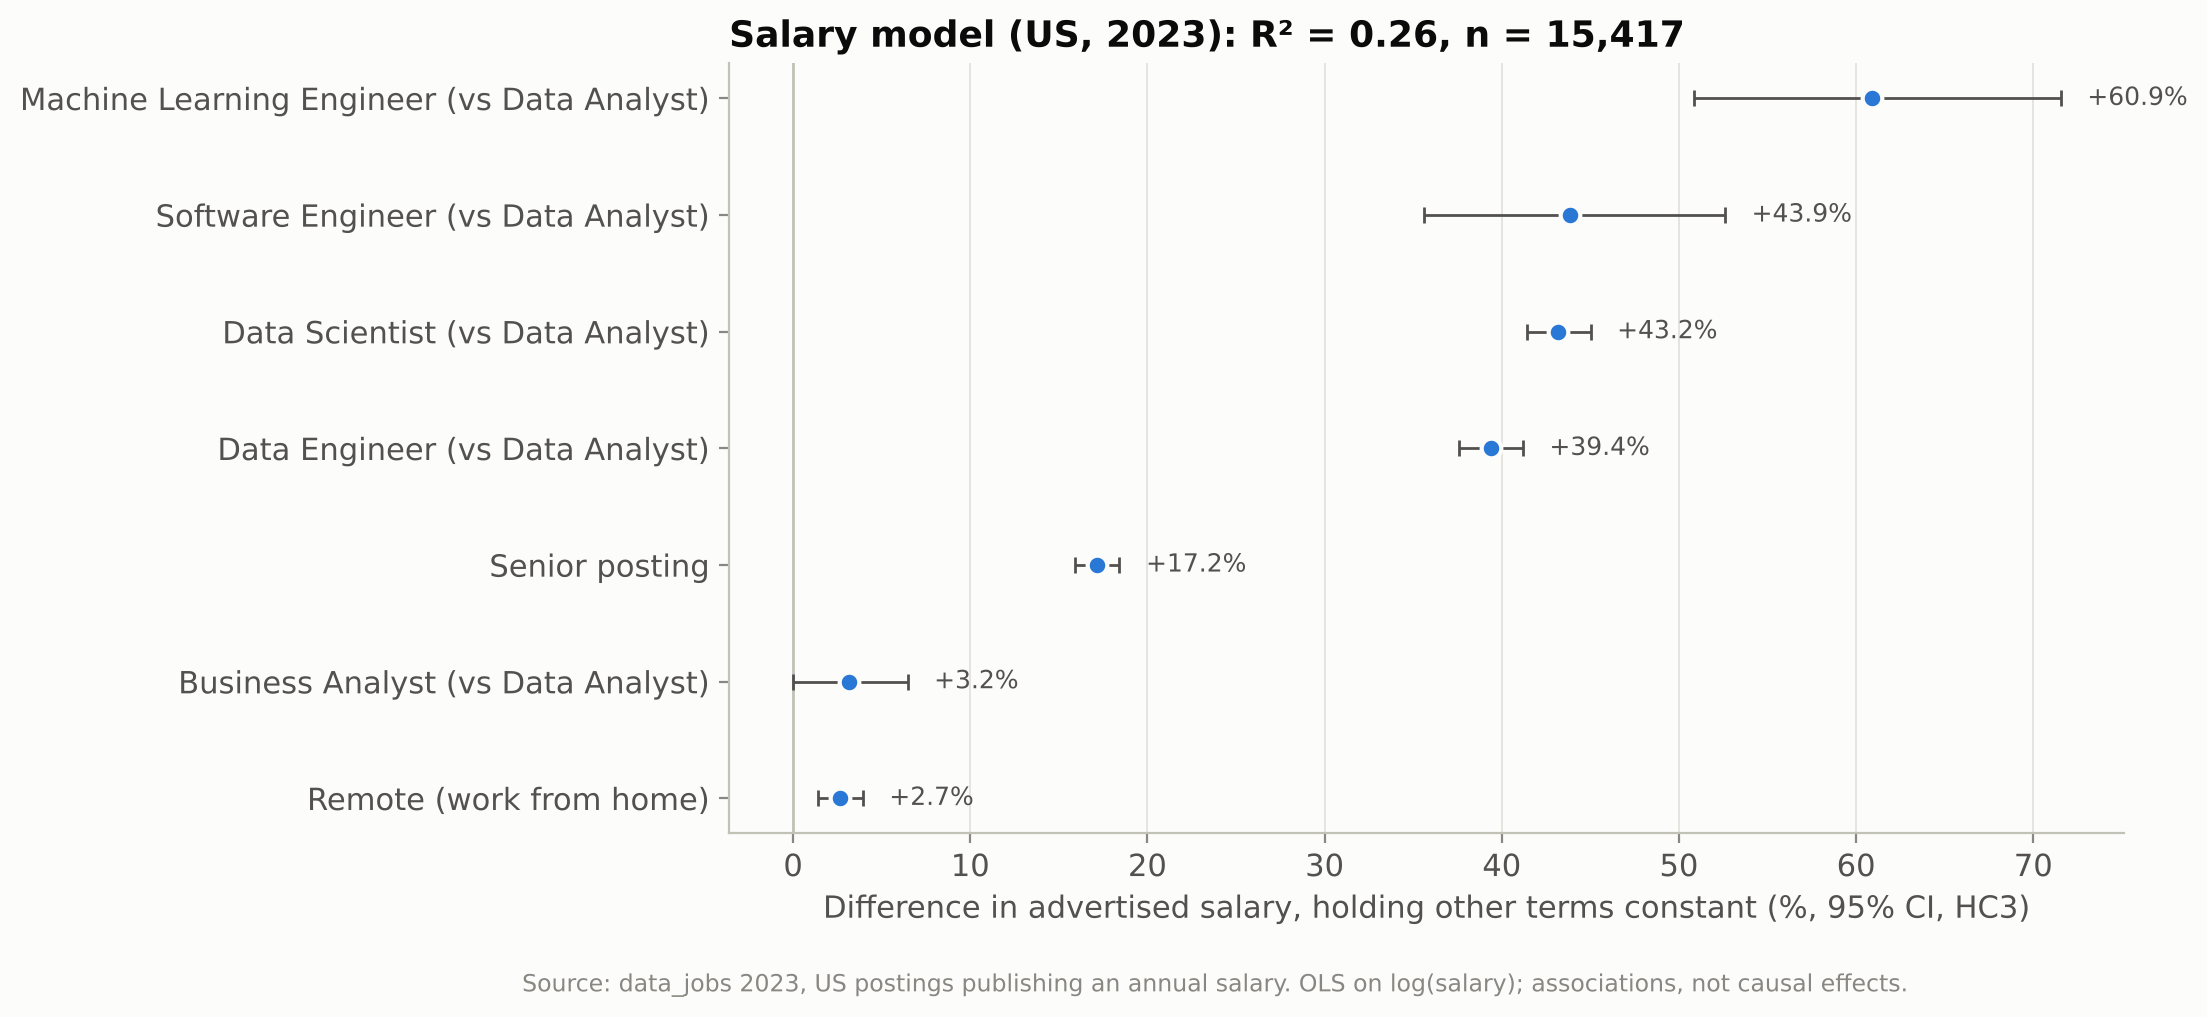

In [12]:
R.fig_salary_coefficients(d)
display(Image(str(R.FIG_DIR / 'D_salary_model.png'), width=750))

**Interpretation:** holding the other terms constant, senior postings advertise about **17% more** (95% CI 15.9-18.4%), ML Engineer postings about 61% more than Data Analyst postings, remote postings about 3% more, and each additional listed skill about 0.3% more. The model explains 26% of the variance: most salary variation comes from factors not in the data (company, city, experience). Residual variance is not constant (Breusch-Pagan), which is why robust standard errors are used. Salaries are published by only 2.8% of postings, a possibly non-random subset.

## 6. Question E: do more experienced profiles list more skills? (live snapshot)
- H0: equal skill-count distributions across employer-stated levels. Kruskal-Wallis + Spearman ρ.
- Run overall **and within description language** (a confounder: the taxonomy detects more skills in English text).

In [13]:
e = A.experience_skill_test(live)
print('English description share by level (%):', e['english_description_share_pct'])
pd.DataFrame(e['results'])[['subset','n','means','kruskal_H','p_value','epsilon_squared','spearman_rho','spearman_p']]

English description share by level (%): {'student_intern': 23.41, 'entry': 17.6, 'mid': 28.79, 'experienced': 31.69, 'lead_manager': 33.33}


,subset,n,means,kruskal_H,p_value,epsilon_squared,spearman_rho,spearman_p
0,all languages,1616,"{'student_intern': 2.68, 'entry': 2.26, 'mid':...",53.392,7.054207e-11,0.0331,0.1330,8.088746e-08
1,English descriptions,456,"{'student_intern': 5.64, 'entry': 5.66, 'mid':...",40.418,3.546224e-08,0.0888,0.1591,6.513719e-04
2,German descriptions,1066,"{'student_intern': 1.76, 'entry': 1.52, 'mid':...",11.203,2.437707e-02,0.0105,0.0669,2.896045e-02


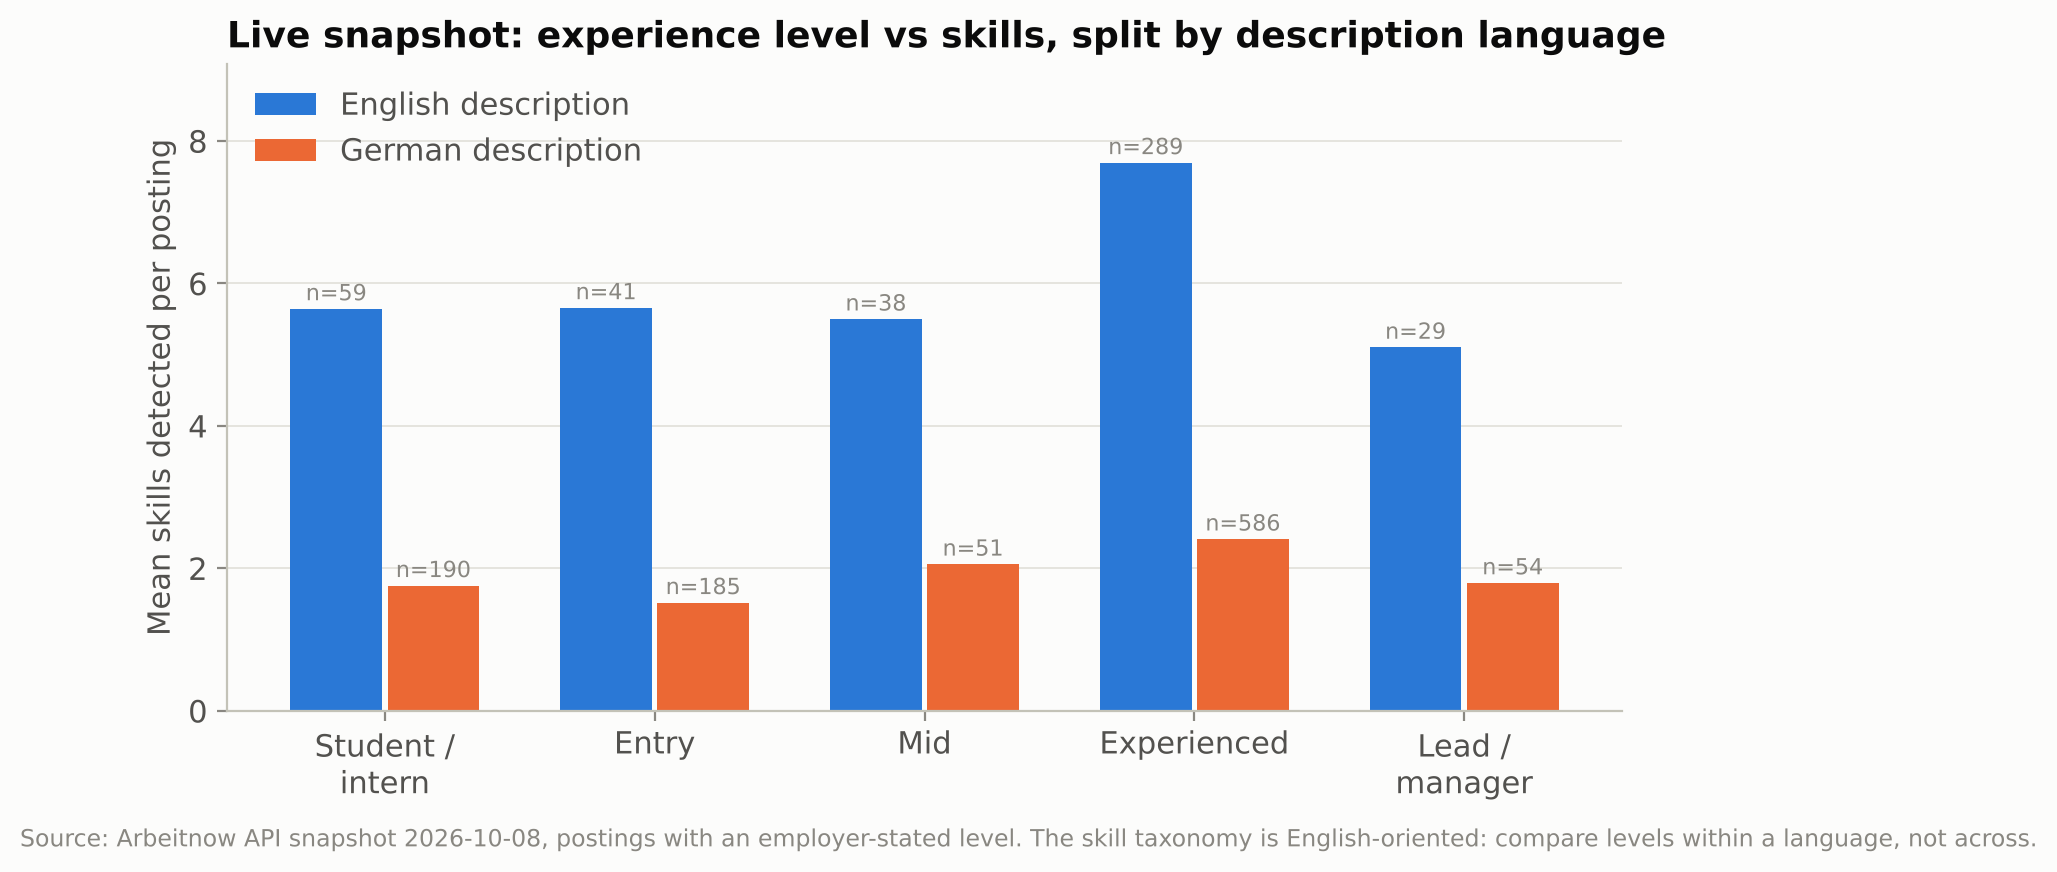

In [14]:
R.fig_experience_skills(live)
display(Image(str(R.FIG_DIR / 'E_experience_level_skills.png'), width=750))

**Interpretation:** 'experienced' postings list the most skills; the relationship is **not monotonic** (lead/manager postings list fewer). The effect is clearer within English descriptions (ε² ≈ 0.09) than within German ones (ε² ≈ 0.01), consistent with the measurement limitation. Small sample (n = 1,616 labelled).

## 7. Feature correlations (Spearman)

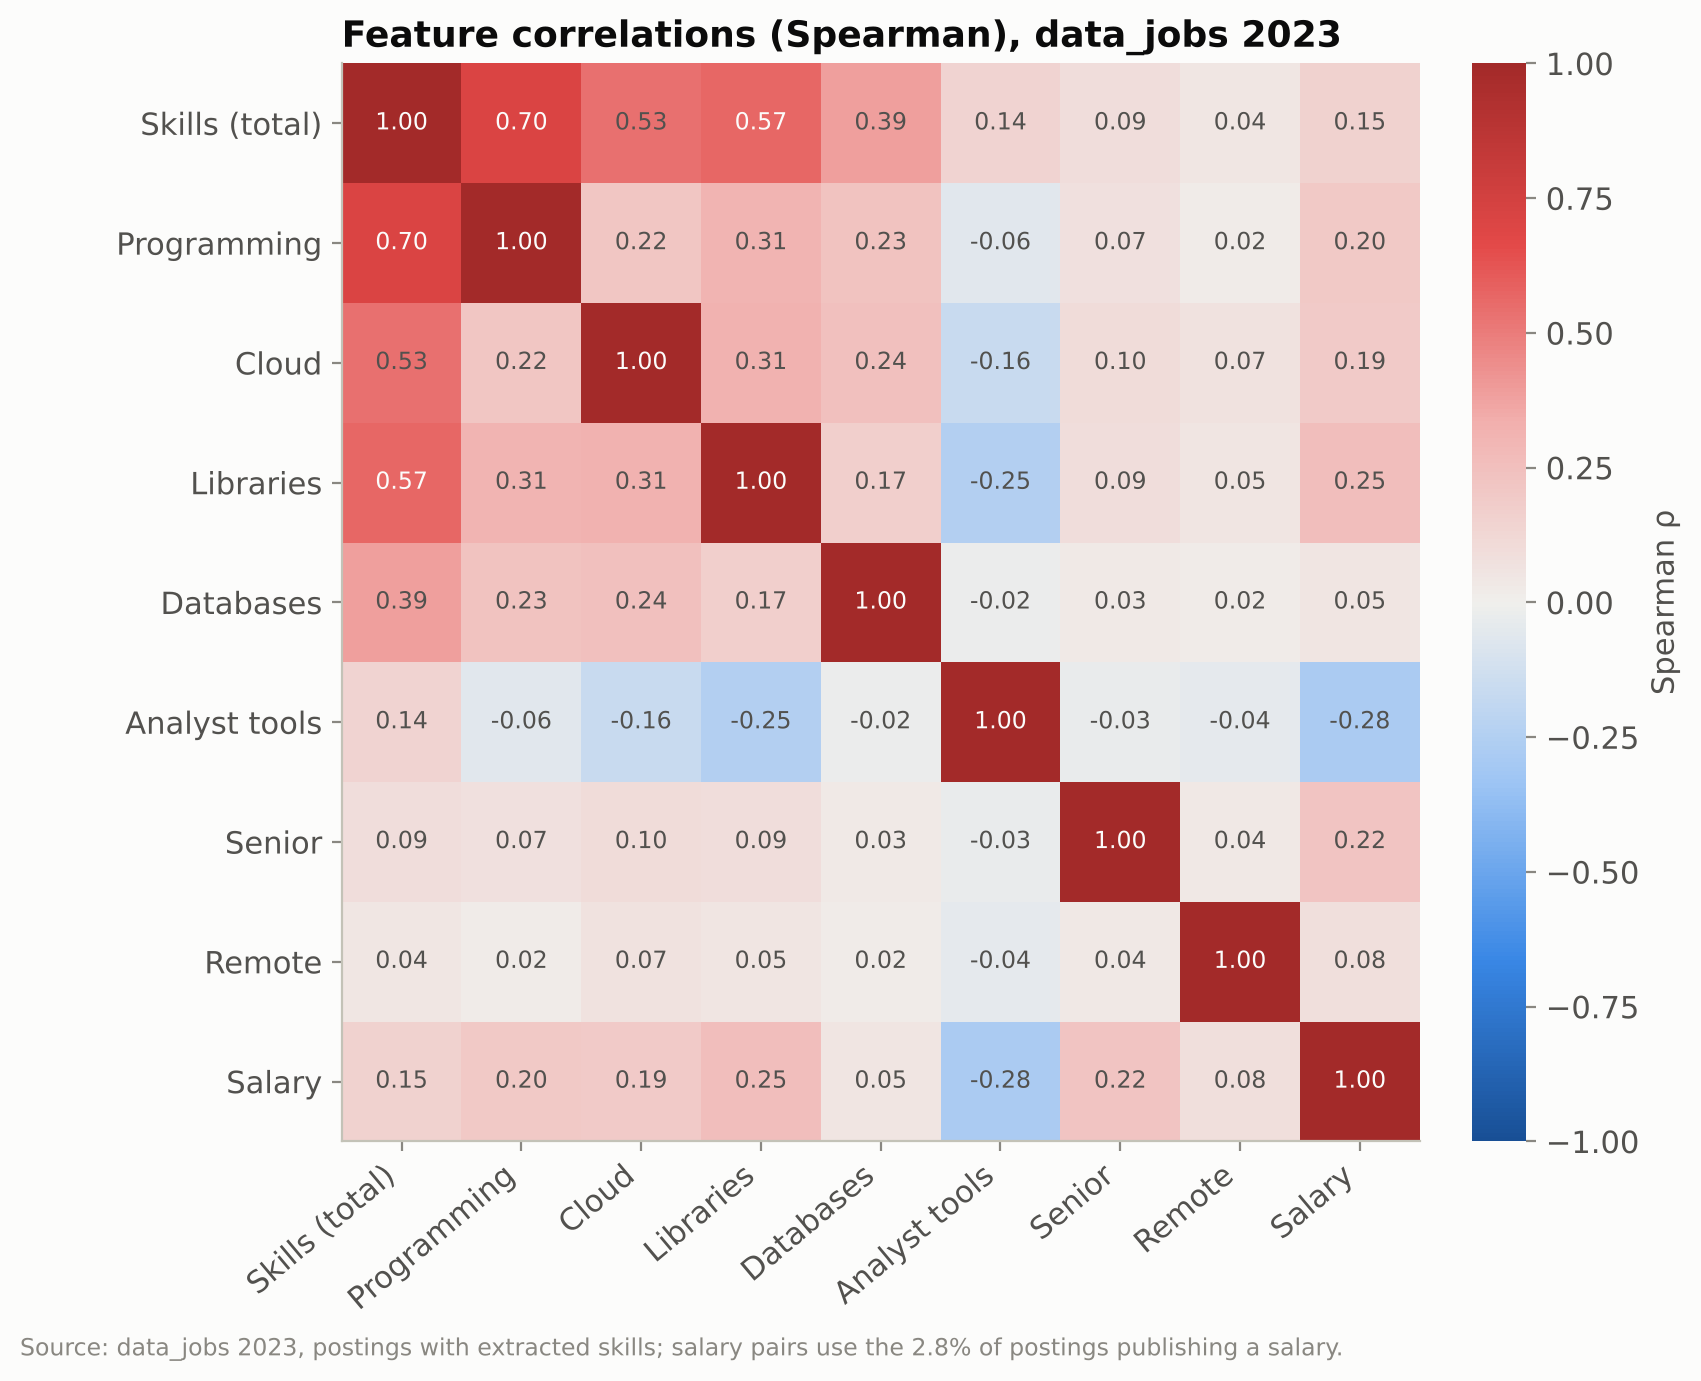

,skill_count,programming_skill_count,cloud_skill_count,libraries_skill_count,databases_skill_count,analyst_tools_skill_count,is_senior,work_from_home,salary_year_avg
skill_count,1.000,0.704,0.534,0.570,0.387,0.145,0.091,0.044,0.153
programming_skill_count,0.704,1.000,0.216,0.309,0.228,-0.057,0.074,0.022,0.197
cloud_skill_count,0.534,0.216,1.000,0.314,0.245,-0.157,0.098,0.066,0.190
libraries_skill_count,0.570,0.309,0.314,1.000,0.170,-0.248,0.087,0.053,0.254
databases_skill_count,0.387,0.228,0.245,0.170,1.000,-0.022,0.029,0.023,0.048
analyst_tools_skill_count,0.145,-0.057,-0.157,-0.248,-0.022,1.000,-0.030,-0.040,-0.281
is_senior,0.091,0.074,0.098,0.087,0.029,-0.030,1.000,0.039,0.223
work_from_home,0.044,0.022,0.066,0.053,0.023,-0.040,0.039,1.000,0.084
salary_year_avg,0.153,0.197,0.190,0.254,0.048,-0.281,0.223,0.084,1.000


In [15]:
corr = A.spearman_correlations(ref)
R.fig_correlations(corr)
display(Image(str(R.FIG_DIR / 'F_feature_correlations.png'), width=650))
corr

Total skills correlates with the per-type counts **by construction** (they are its parts). Salary correlates most with library (ρ = 0.25) and programming skills (0.20) and seniority (0.22), and negatively with analyst tools (-0.28, typical of lower-paid analyst roles). Correlations between dummy variables are approximate.

## 8. Limitations
- Observational postings: associations only, no causal claims.
- Reference data: 2023, data roles, collector's search locations; seniority label derived from titles; skills keyword-extracted by the dataset author.
- Salary: 2.8% of postings, US-heavy, advertised (not actual) pay.
- Live data: one week, Germany-centred, rule-based labels, English-oriented skill taxonomy.
- Large n: p-values are uninformative on their own; read the effect sizes.